## Dataset Selection & Justification

**Dataset:** Predict Students' Dropout and Academic Success

**Source:** UCI Machine Learning Repository
https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

**License:** Creative Commons Attribution 4.0 International (CC BY 4.0)

### Dataset Goal
The dataset is used to predict a student's academic status at the end of the normal course duration: **Dropout**, **Enrolled**, or **Graduate**. In our system, this prediction supports academic advisors and university administrators in identifying at-risk students early, allocating support resources, and designing targeted retention interventions.

### Justification
- **Relevance:** The dataset was collected specifically to study student dropout and academic success in higher education, which aligns directly with our goal of identifying at-risk students. The timing of the available features is discussed in the *Note on Prediction Timing* at the end of this section. Its three-class target supports the multi-class classification required in Phase 1 and provides ground truth for external cluster validation (BCubed) in Phase 2.
- **Completeness:** It contains 4,424 student records and 36 features covering demographic, socioeconomic, macroeconomic, and academic information. This range of attributes allows us to analyze several factors behind student outcomes rather than relying on grades alone. The source reports no missing values.
- **Quality:** The data comes from real institutional records and is published on the UCI Machine Learning Repository, a widely used and curated source. It is structured and tabular, meets the project's size requirements (several hundred rows and at least 10 to 15 features), and can be read directly in Python.

## Initial Data Inspection

This section examines the structure and quality of the student dataset, including its dimensions, data types, missing values, descriptive statistics, and target class distribution.

In [2]:

import pandas as pd
from pathlib import Path
from io import BytesIO

# Search for the dataset in common project locations
paths = [
    Path("Dataset/data.csv"),
    Path("data.csv")
]

dataset_path = next((p for p in paths if p.exists()), None)

if dataset_path:
    df = pd.read_csv(dataset_path, sep=";")
else:
    try:
        from google.colab import files

        print("Upload Dataset/data.csv to continue.")
        uploaded = files.upload()

        if "data.csv" not in uploaded:
            raise FileNotFoundError("Please upload data.csv.")

        df = pd.read_csv(
            BytesIO(uploaded["data.csv"]),
            sep=";"
        )
    except ImportError:
        raise FileNotFoundError(
            "Dataset not found. Make sure Dataset/data.csv is available."
        )

print("Dataset loaded successfully:", df.shape)


Upload Dataset/data.csv to continue.


Saving data.csv to data.csv
Dataset loaded successfully: (4424, 37)


In [3]:
# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Number of features:", df.shape[1] - 1)

Number of rows: 4424
Number of columns: 37
Number of features: 36


**Dataset Overview**

The dataset contains 4,424 student records and 37 columns, including 36 input features and one target variable. The target variable represents three academic outcomes: Dropout, Enrolled, and Graduate.

In [4]:
# Inspect column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

**Data Types Analysis**

The dataset contains 29 integer columns, 7 floating-point columns, and 1 object column (Target). Most features are stored numerically, although some represent categorical variables encoded as integers.

In [5]:
# Check missing values
missing_values = df.isnull().sum()

print(missing_values)
print("\nTotal missing values:", missing_values.sum())

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

### Missing Values Analysis

The dataset contains no missing values across all 37 columns. This indicates that all 4,424 student records are complete, and no missing-value imputation is required during preprocessing.

In [6]:
# Display descriptive statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance\t,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


**Statistical Summary Analysis**

The dataset contains 4,424 student records. The average age at enrollment is 23.27 years, and the average admission grade is 126.98. The average first-semester grade (10.64) is slightly higher than the second-semester grade (10.23). Some numerical variables represent categorical codes and should not be interpreted as continuous measurements.

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


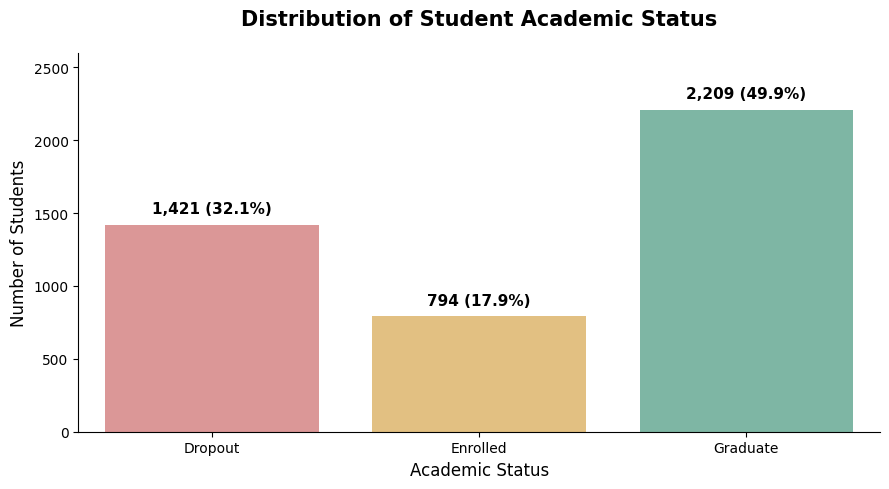

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count students in each academic status
order = ["Dropout", "Enrolled", "Graduate"]
class_counts = df["Target"].value_counts()
print(class_counts)

# Create a professional bar chart
plt.figure(figsize=(9, 5))
colors = ["#E78B8B", "#F2C572", "#75BFA8"]

ax = sns.barplot(
    x=order,
    y=[class_counts[status] for status in order],
    hue=order,
    palette=colors,
    legend=False
)

# Add counts and percentages above bars
total = len(df)

for bar in ax.patches:
    count = int(bar.get_height())
    percentage = count / total * 100
    ax.annotate(
        f"{count:,} ({percentage:.1f}%)",
        (bar.get_x() + bar.get_width()/2, count),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        xytext=(0, 6),
        textcoords="offset points"
    )

plt.title("Distribution of Student Academic Status",
          fontsize=15, fontweight="bold", pad=20)
plt.xlabel("Academic Status", fontsize=12)
plt.ylabel("Number of Students", fontsize=12)
plt.ylim(0, 2600)
sns.despine()
plt.tight_layout()
plt.show()


**Class Distribution Analysis**

The dataset contains 2,209 graduates, 1,421 dropouts, and 794 enrolled students. Graduates represent the largest class, while enrolled students represent the smallest. This indicates a class imbalance that should be considered during preprocessing and model evaluation.

## Exploratory Data Analysis: Feature Relationships

This section analyzes the relationships between features and the student outcome using histograms, box plots, a correlation heatmap, mutual information, and proportion charts.

### Setup

In [8]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Some original column names contain trailing spaces or tabs, so we clean them.
df.columns = df.columns.str.strip()

# Readable target label column, used only for plotting.
# Works whether the target is stored as text or as codes (0, 1, 2).
target_map = {0: "Dropout", 1: "Enrolled", 2: "Graduate"}
if pd.api.types.is_numeric_dtype(df["Target"]):
    df["Target_label"] = df["Target"].map(target_map)
else:
    df["Target_label"] = df["Target"].astype(str).str.strip()

class_order = ["Dropout", "Enrolled", "Graduate"]
palette = {"Dropout": "#d62728", "Enrolled": "#ff7f0e", "Graduate": "#2ca02c"}

### Feature Groups

Many columns in this dataset are stored as integers but are actually **categorical codes** (for example, `Course`, `Marital status`, and `Application mode`). Treating these codes as numbers would produce misleading histograms and correlations, so we separate the features into groups and choose a suitable plot for each group.

In [9]:
# Continuous / count features: suitable for histograms and box plots
numeric_features = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
]

# Binary (0/1) features: suitable for proportion bar charts against the target
binary_features = {
    "Tuition fees up to date": {0: "No", 1: "Yes"},
    "Scholarship holder": {0: "No", 1: "Yes"},
    "Debtor": {0: "No", 1: "Yes"},
    "Gender": {0: "Female", 1: "Male"},
    "Displaced": {0: "No", 1: "Yes"},
    "International": {0: "No", 1: "Yes"},
}

# Safety check: confirm every listed column exists in the loaded file
missing = [c for c in numeric_features + list(binary_features) if c not in df.columns]
print("Missing columns:", missing if missing else "none")

Missing columns: none


### 1. Feature Distributions (Histograms)

Histograms show the shape of each numeric feature: whether it is symmetric or skewed, where most values fall, and whether there are unusual spikes.

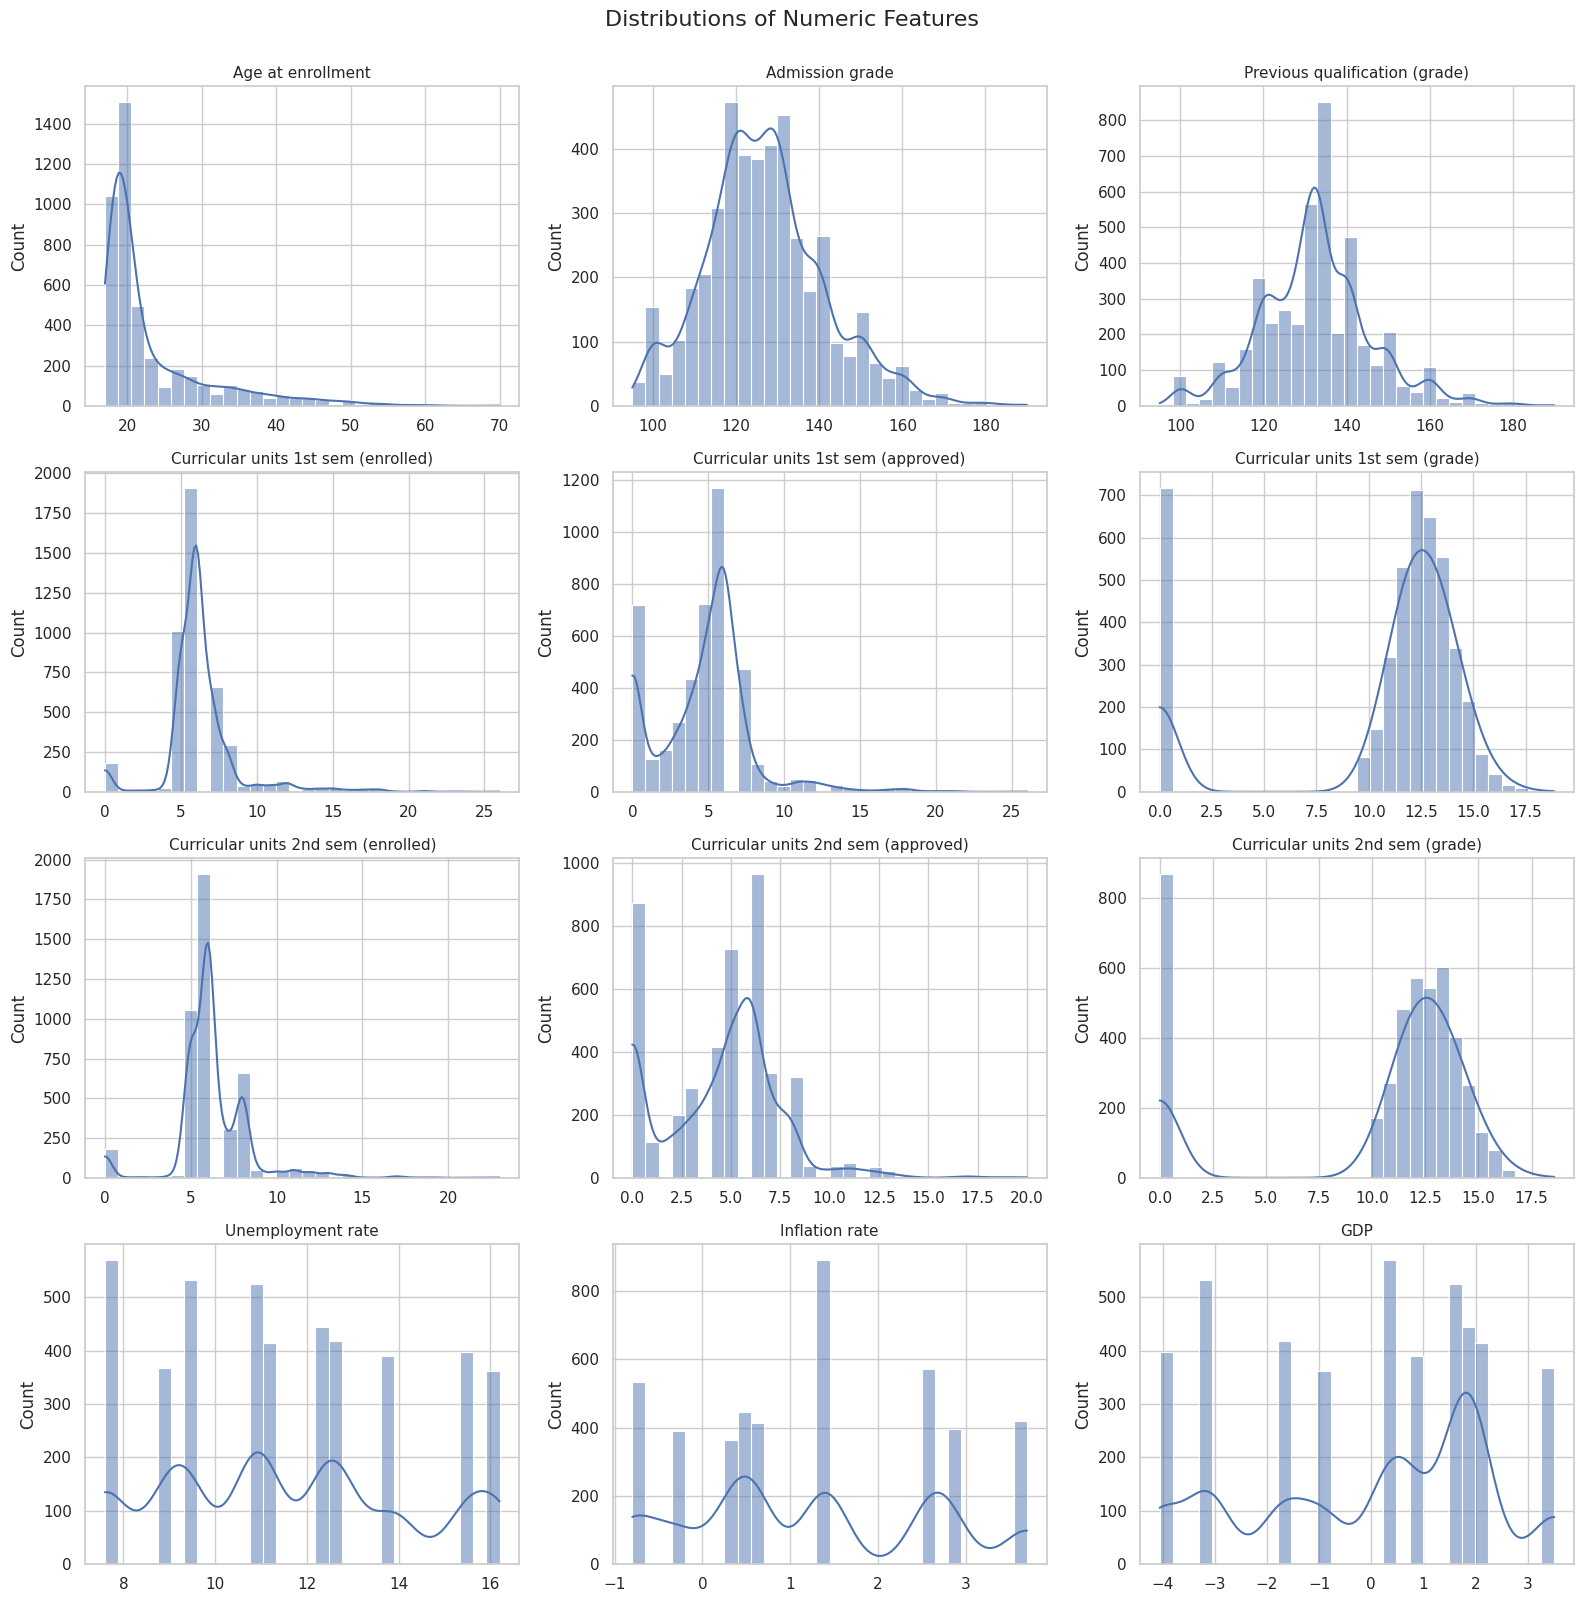

In [10]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for ax, col in zip(axes.flat, numeric_features):
    sns.histplot(df[col], kde=True, bins=30, ax=ax, color="#4c72b0")
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
fig.suptitle("Distributions of Numeric Features", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

**Observations:**
- **Age at enrollment** is strongly right-skewed. The median age is 20, about 76% of students are 25 or younger, and a long tail of older students reaches up to 70.
- **Admission grade** and **Previous qualification (grade)** are roughly bell-shaped, with most students in the middle of the grading scale.
- The **curricular unit grade** features show a noticeable spike at **0**, affecting approximately 16% of students in the 1st semester and 20% in the 2nd semester. Every student with a zero grade has zero approved units in that semester, and every student with zero approved units has a zero grade. This suggests that the grade represents the average of approved units only and is recorded as 0 when no units are approved. Some of these students have recorded evaluations while others do not, so a zero grade does not necessarily mean that the student was not evaluated. These values were retained because they are recorded in the dataset, and their interpretation requires further verification before treating them as missing values or errors.
- **Unemployment rate**, **Inflation rate**, and **GDP** take only 9 to 10 distinct values each, because they describe the economic situation in the student's year of enrollment rather than the individual student.

### 2. Numeric Features by Target Class (Box Plots)

Box plots compare the distribution of each numeric feature across the three outcome classes. Large differences in the median or spread between classes suggest that a feature is associated with the outcome. Points outside the whiskers are potential outliers.

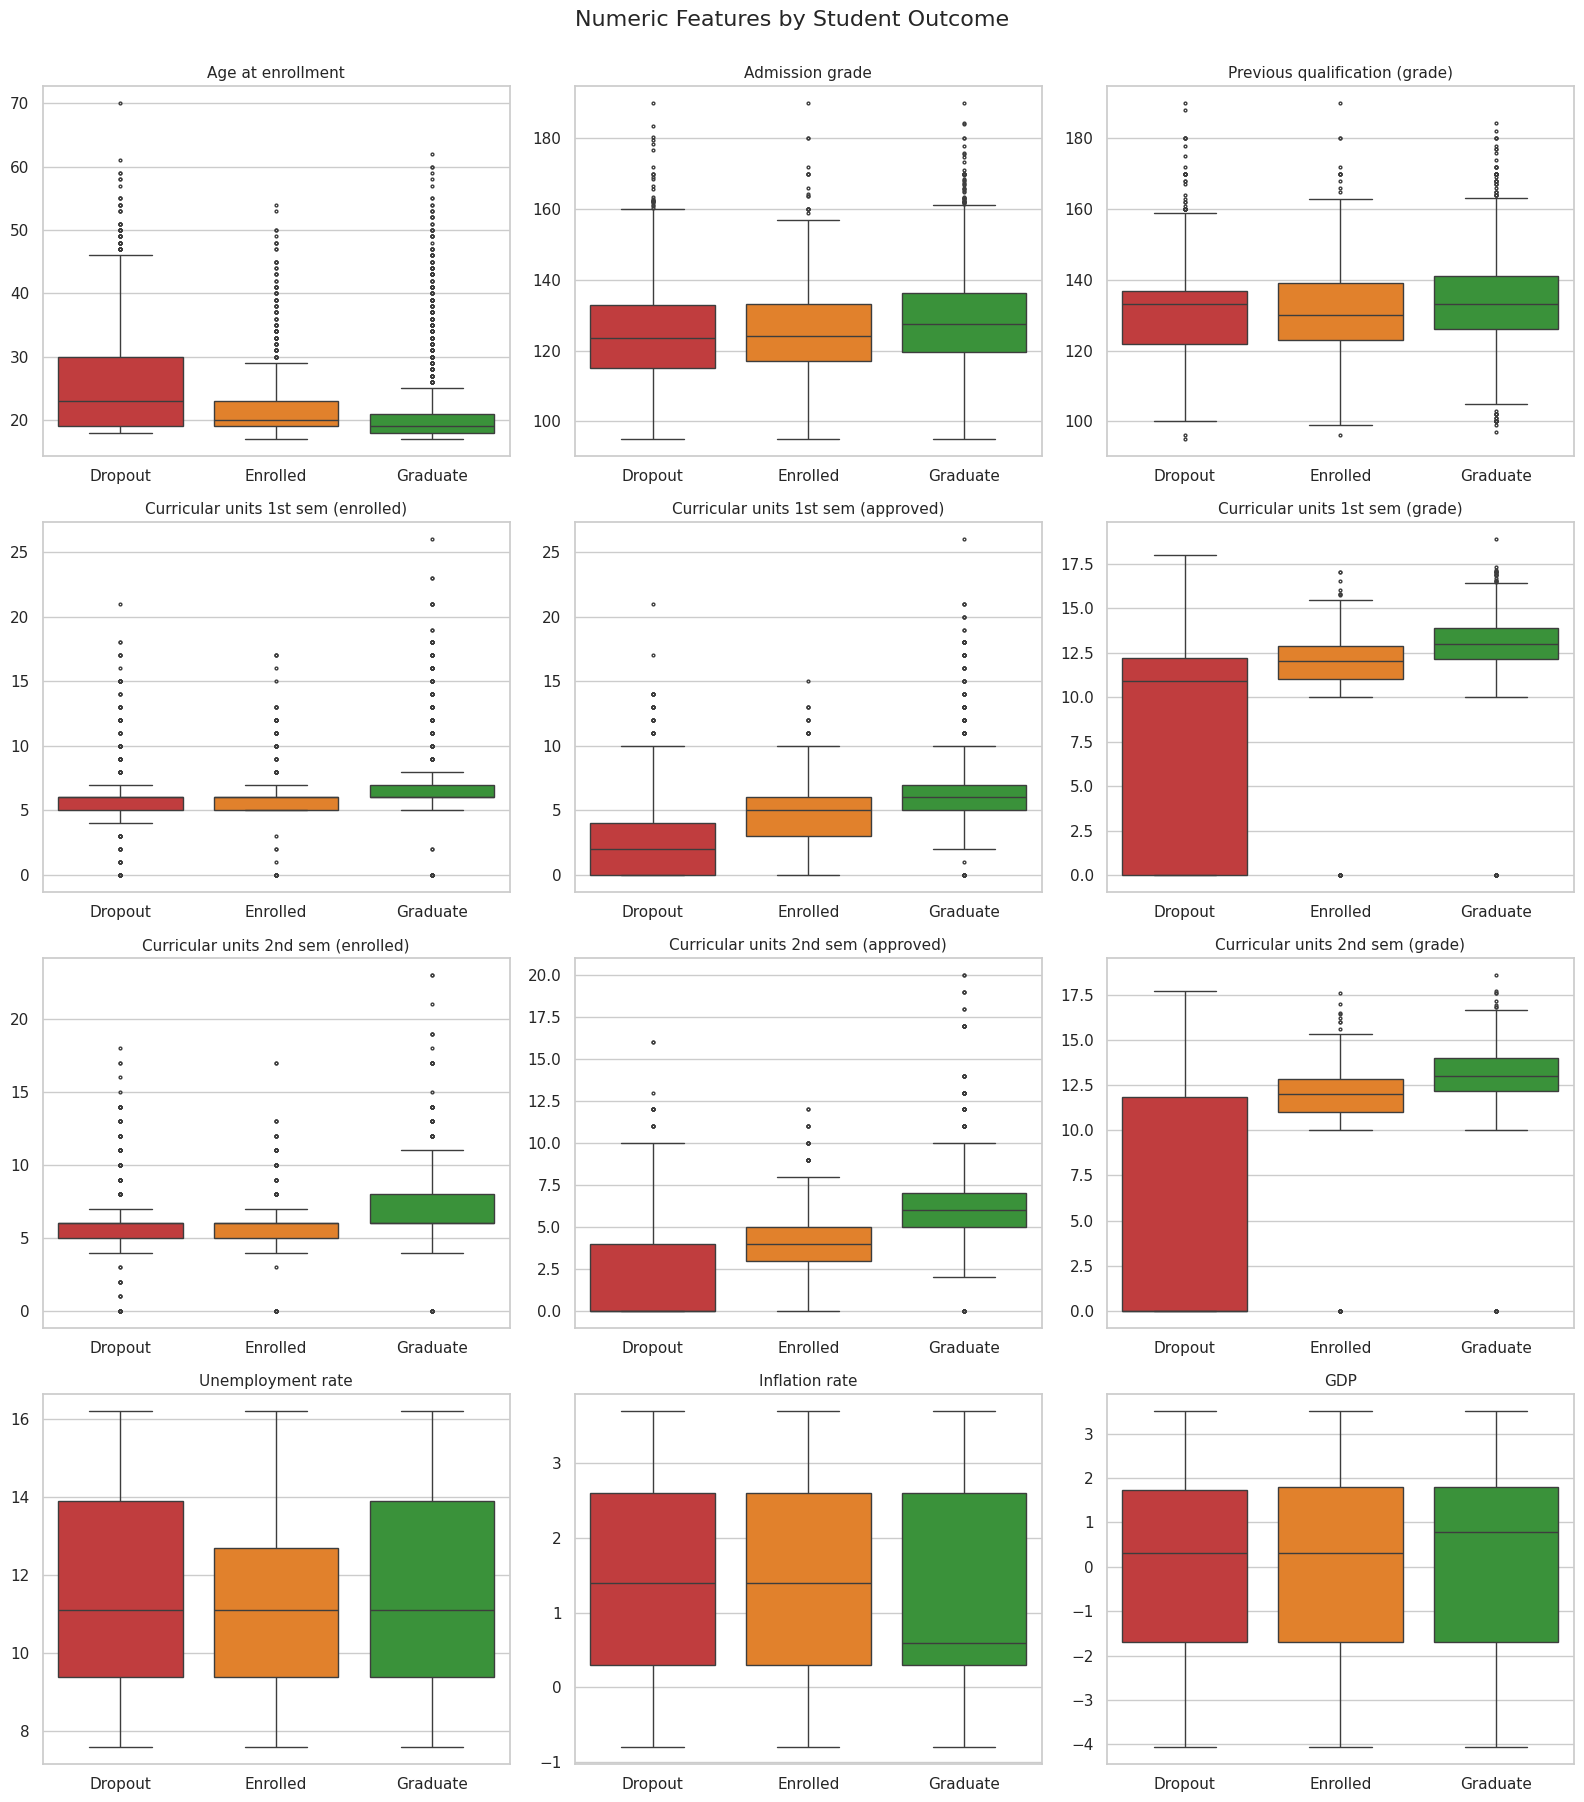

In [11]:
fig, axes = plt.subplots(4, 3, figsize=(16, 18))
for ax, col in zip(axes.flat, numeric_features):
    sns.boxplot(data=df, x="Target_label", y=col, order=class_order,
                palette=palette, ax=ax, fliersize=2)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Numeric Features by Student Outcome", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

**Observations:**
- The **1st and 2nd semester approved units and grades** show the clearest visual separation between classes. For example, the median number of approved units in the 2nd semester is 0 for dropouts, 4 for enrolled students, and 6 for graduates.
- **Dropout** students tend to be **older at enrollment**, with a median age of 23 compared with 19 for graduates.
- **Admission grade** differs only slightly between classes (median of about 124 for dropouts vs. 127 for graduates), and **Previous qualification (grade)** has almost the same median across classes.
- The **Enrolled** class tends to fall between Dropout and Graduate and overlaps with both. This suggests it may be harder to separate, but this must be confirmed with the classification results in Part B.
- Several features contain outliers (for example, very high ages). These are plausible real values, so we keep them rather than removing them.
- These plots show **associations only**. They do not show that a feature causes an outcome or that it predicts the outcome independently of other features.

### 3. Correlation Heatmap (Continuous Features Only)

The heatmap shows the Pearson correlation between the **continuous and count features only**. Two groups of columns are deliberately excluded:

- **The target**, because its classes (Dropout, Enrolled, Graduate) are categories. Encoding them as 0, 1, and 2 would assume equal distances between outcomes, which makes a Pearson correlation with the target misleading.
- **Categorical code columns** (such as `Course`, `Marital status`, and `Application mode`), because their numeric codes have no real order.

The relationship between features and the target is analyzed separately in the box plots, the binary feature charts, and the mutual information analysis.

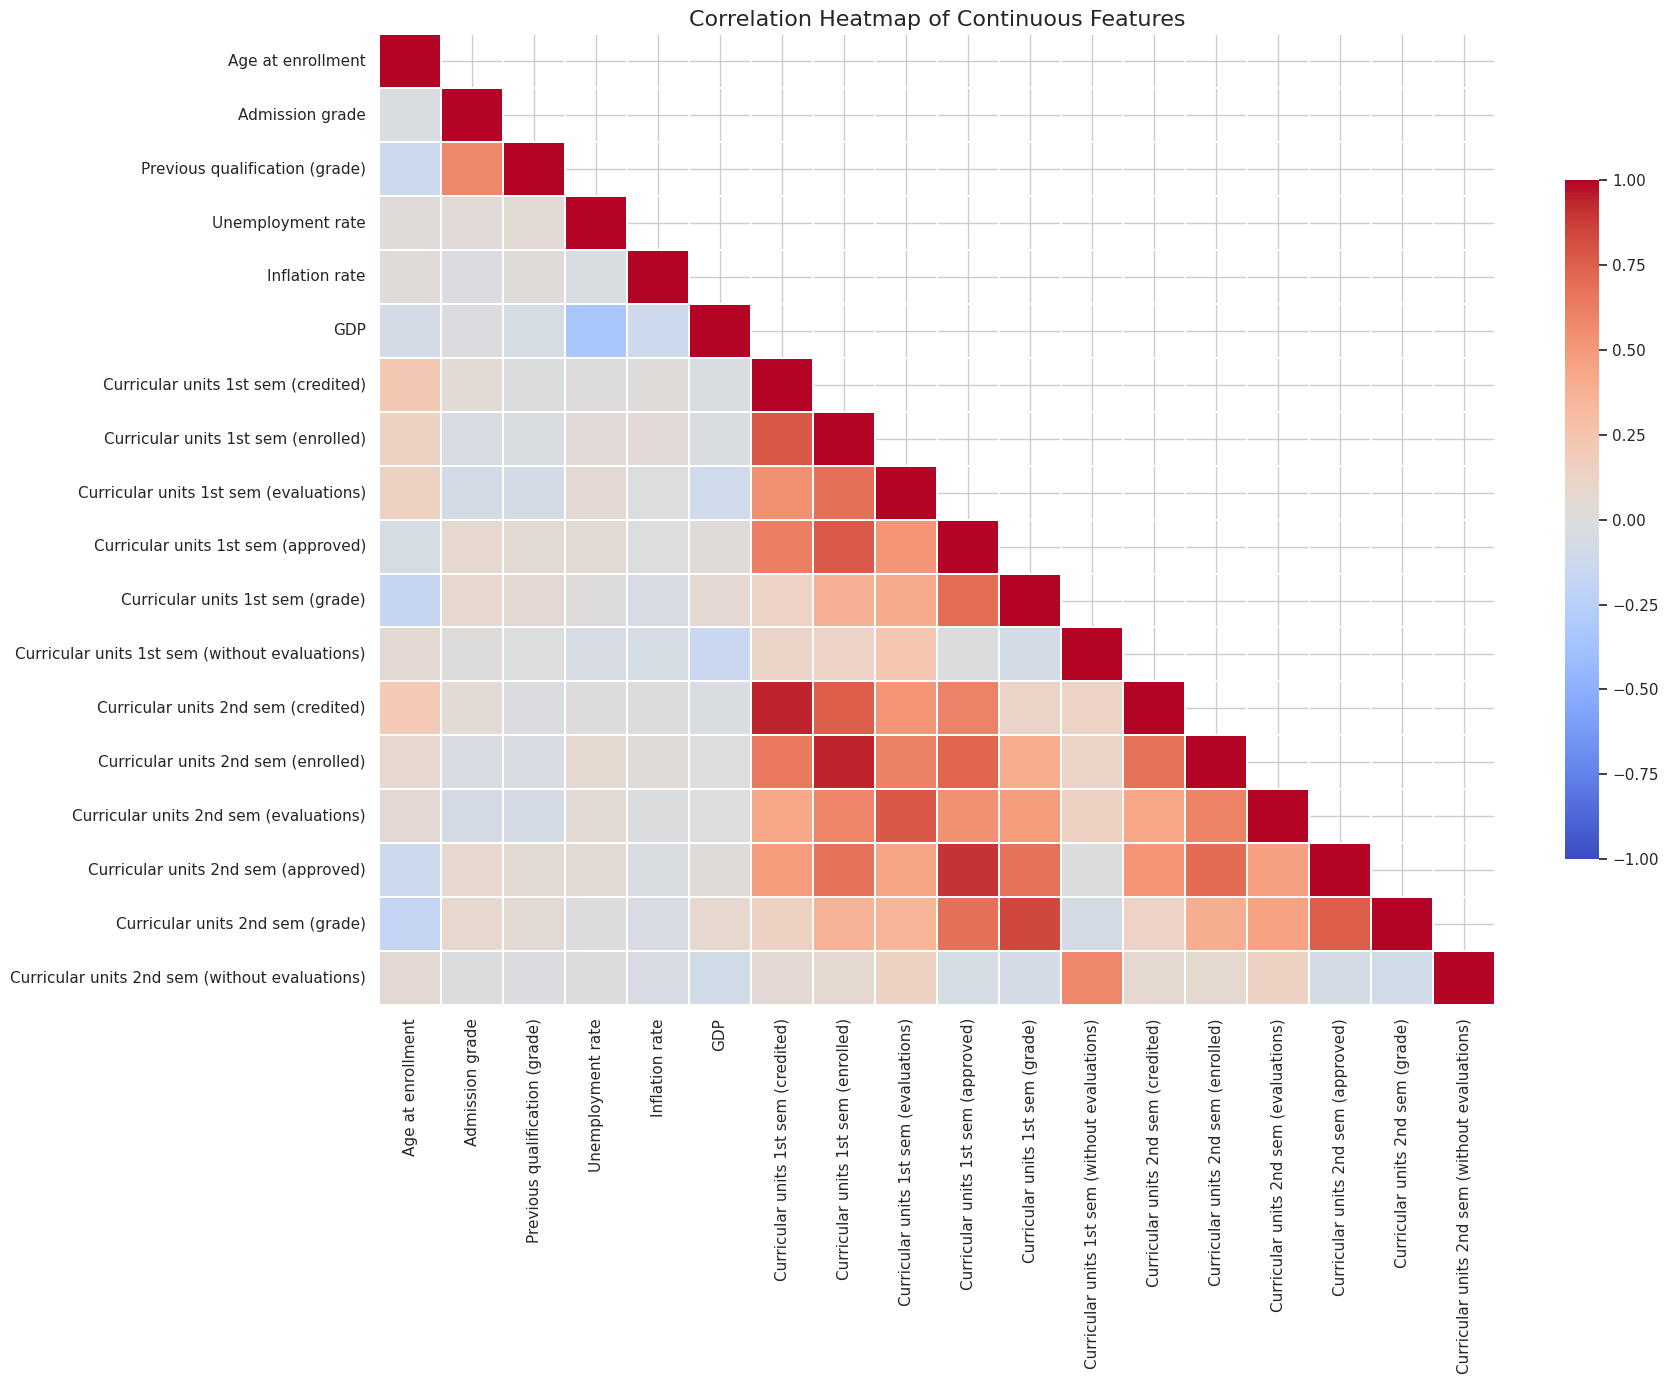

In [12]:
# Continuous and count features only (no target, no categorical codes)
heatmap_features = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
] + [
    f"Curricular units {sem} sem ({kind})"
    for sem in ["1st", "2nd"]
    for kind in ["credited", "enrolled", "evaluations", "approved", "grade", "without evaluations"]
]

corr = df[heatmap_features].corr()

plt.figure(figsize=(18, 14))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # hide the duplicate upper triangle
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Correlation Heatmap of Continuous Features", fontsize=16)
plt.tight_layout()
plt.show()

In [13]:
# Highly correlated feature pairs (possible redundancy)
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack()
             .reset_index())
pairs.columns = ["Feature 1", "Feature 2", "Correlation"]
high_pairs = pairs[pairs["Correlation"].abs() >= 0.8].sort_values("Correlation", ascending=False)
high_pairs.reset_index(drop=True)

,Feature 1,Feature 2,Correlation
0,Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.944811
1,Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.942627
2,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.904002
3,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.837170


**Observations:**
- Several **1st and 2nd semester curricular unit features are strongly correlated with each other** (for example, approved units in the 1st semester vs. the 2nd semester). This indicates **redundancy**. In the preprocessing step, the team can consider combining them (for example, an approval ratio) or removing some of them to reduce multicollinearity.
- **Admission grade** and **Previous qualification (grade)** are moderately correlated (about 0.58), which is expected because admission is partly based on prior results.
- The macroeconomic features (**Unemployment rate**, **Inflation rate**, **GDP**) show weak correlations with the student-level features (all below about 0.15 in absolute value), which is expected because they describe the economy rather than the individual student.

### 4. Preliminary Feature–Target Association (Mutual Information)

To measure how much each feature is associated with the target **without** treating the classes as numbers, we use **mutual information**. It measures how much knowing a feature reduces uncertainty about the outcome class, and it can capture non-linear relationships. Binary and categorical code columns are marked as discrete so their codes are not treated as ordered values.

This is a **preliminary, exploratory** analysis. Mutual information looks at each feature on its own, so it does not show whether a feature remains useful once other features are taken into account. Final feature importance will be assessed with the supervised models in Part B.

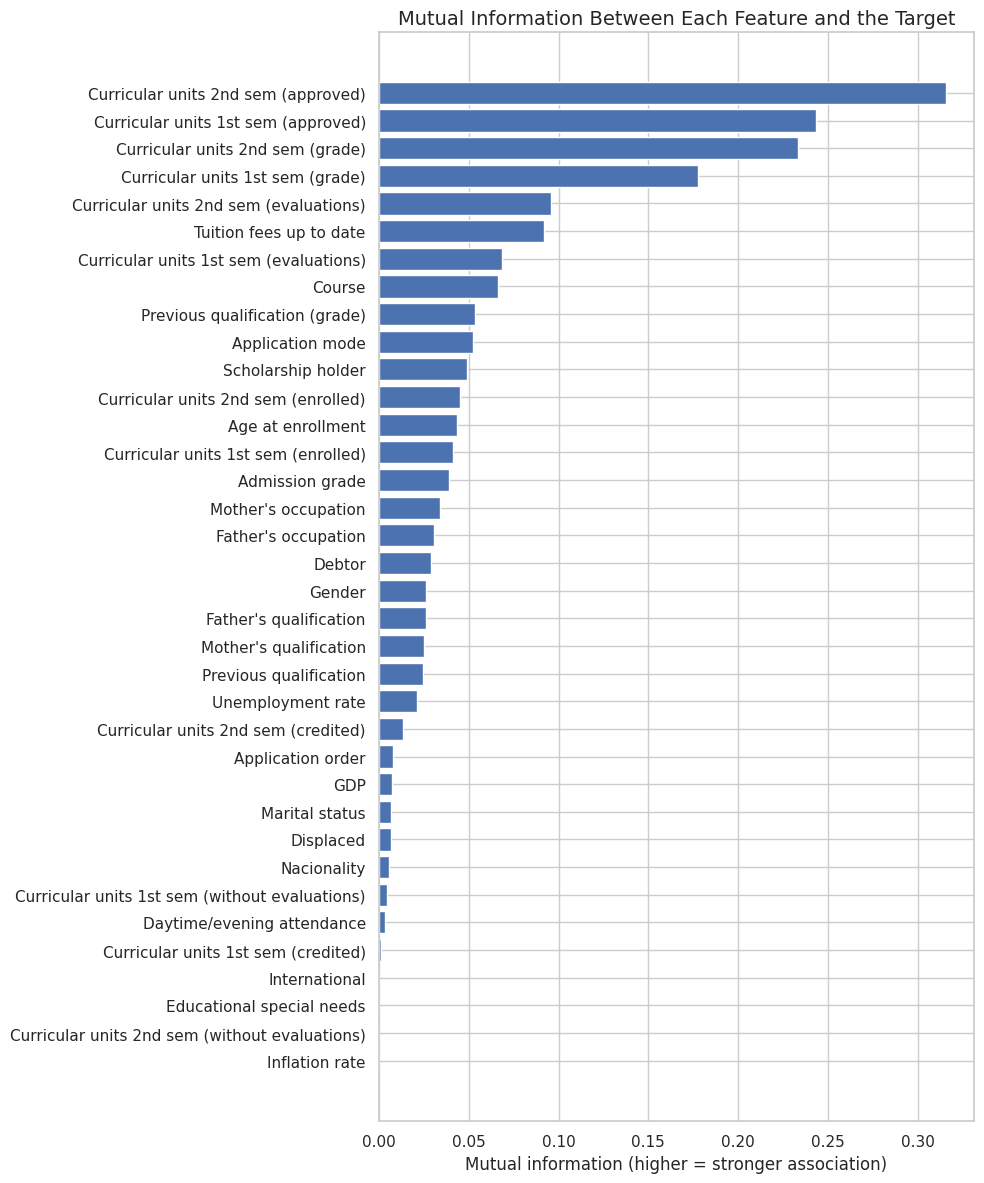

,0
Curricular units 2nd sem (approved),0.315642
Curricular units 1st sem (approved),0.243411
Curricular units 2nd sem (grade),0.233241
Curricular units 1st sem (grade),0.177916
Curricular units 2nd sem (evaluations),0.095685
Tuition fees up to date,0.091828
Curricular units 1st sem (evaluations),0.068761
Course,0.066468
Previous qualification (grade),0.053209
Application mode,0.052221


In [14]:
from sklearn.feature_selection import mutual_info_classif

X_mi = df.drop(columns=["Target", "Target_label"])
y_mi = df["Target_label"]

# Columns that are binary or categorical codes are treated as discrete
discrete_mask = [col not in heatmap_features for col in X_mi.columns]

mi = mutual_info_classif(X_mi, y_mi, discrete_features=discrete_mask, random_state=42)
mi_scores = pd.Series(mi, index=X_mi.columns).sort_values()

plt.figure(figsize=(10, 12))
plt.barh(mi_scores.index, mi_scores.values, color="#4c72b0")
plt.title("Mutual Information Between Each Feature and the Target", fontsize=14)
plt.xlabel("Mutual information (higher = stronger association)")
plt.tight_layout()
plt.show()

mi_scores.sort_values(ascending=False).head(10)

**Observations:**
- The features with the highest mutual information are the **1st and 2nd semester approved units and grades**. They are followed by the semester **evaluations** features and **Tuition fees up to date**, which is the highest-ranked feature that does not depend on semester performance.
- Other features with noticeable scores include **Course**, **Application mode**, **Previous qualification (grade)**, and **Scholarship holder**.
- Features with mutual information close to zero show little individual association with the outcome in this analysis, although they may still contribute in combination with other features.

### 5. Binary Features vs. Target

For each binary feature, the chart shows the **percentage of students in each outcome class**. Comparing the bars within a chart shows whether the outcome distribution differs between the two groups of that feature.

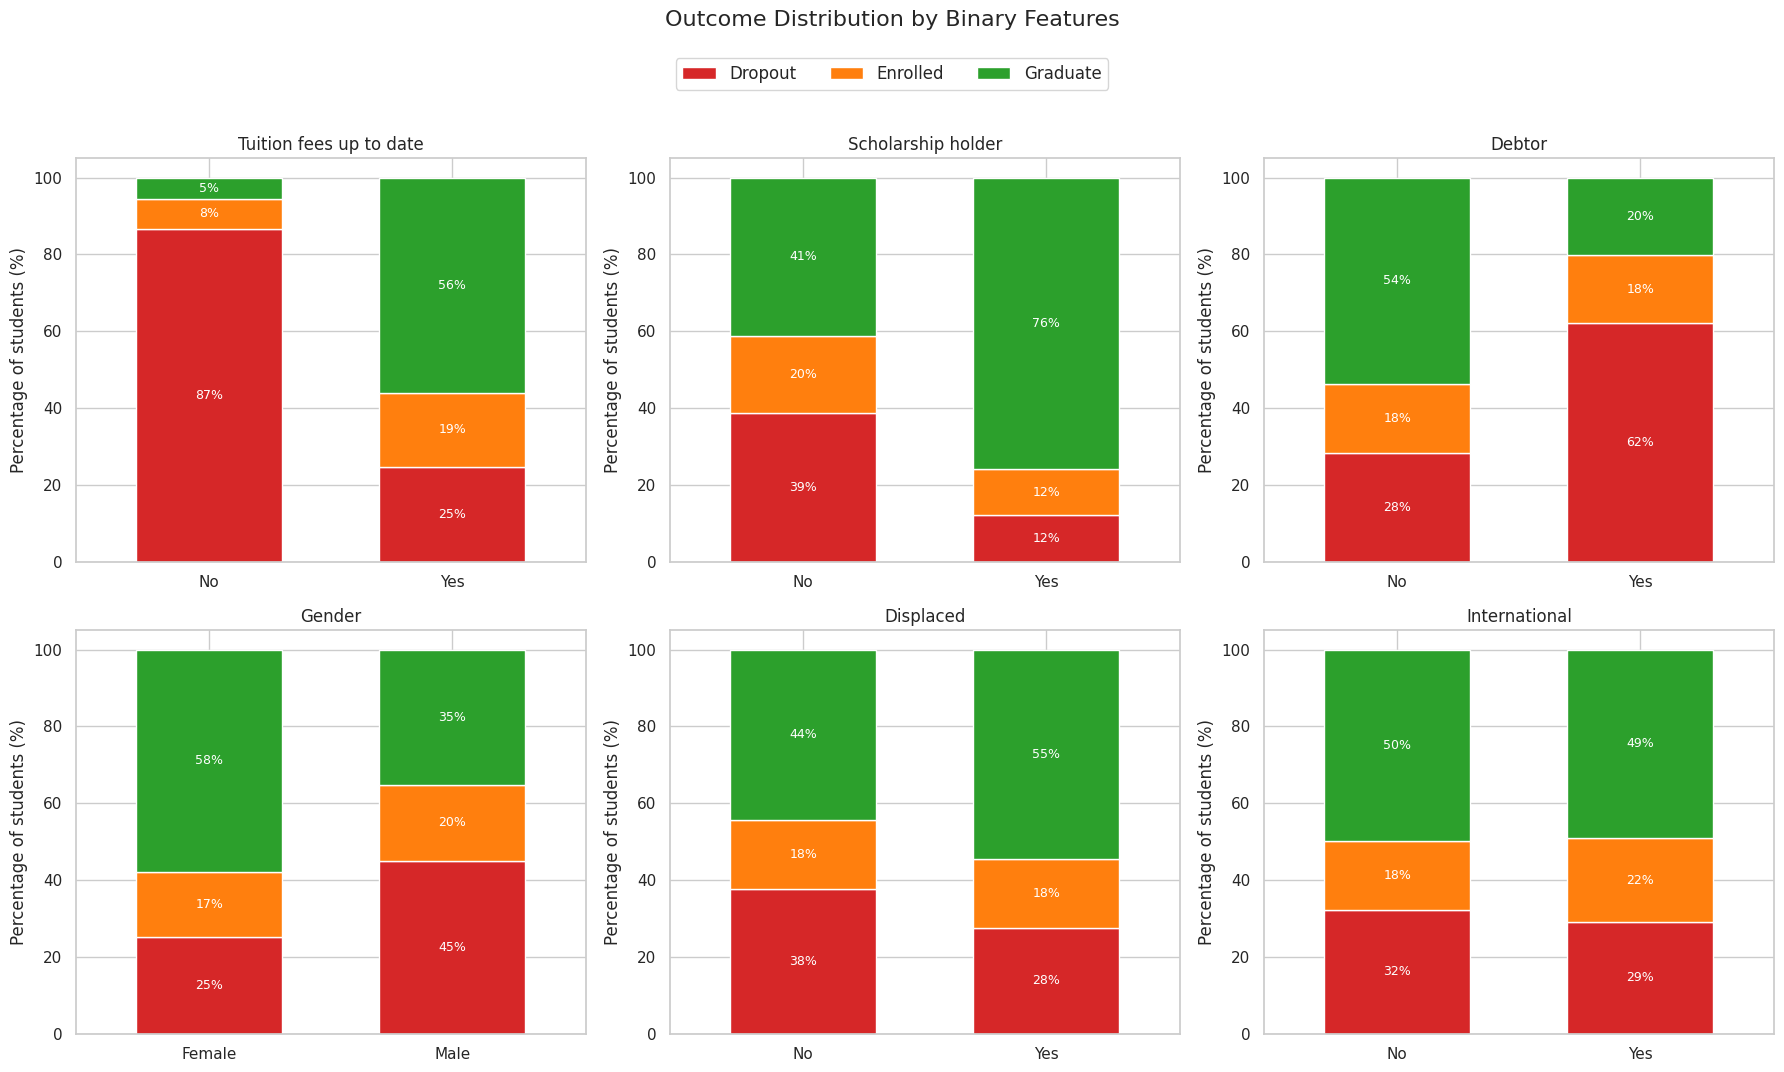

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (col, labels) in zip(axes.flat, binary_features.items()):
    ct = pd.crosstab(df[col].map(labels), df["Target_label"], normalize="index") * 100
    ct = ct[class_order]
    ct.plot(kind="bar", stacked=True, ax=ax,
            color=[palette[c] for c in class_order], width=0.6, legend=False)
    ax.set_title(col, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Percentage of students (%)")
    ax.tick_params(axis="x", rotation=0)
    # Label each segment with its percentage
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f%%", label_type="center", fontsize=9, color="white")

handles, leg_labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, leg_labels, loc="upper center", ncol=3, fontsize=12, bbox_to_anchor=(0.5, 1.03))
fig.suptitle("Outcome Distribution by Binary Features", fontsize=16, y=1.07)
plt.tight_layout()
plt.show()

**Observations:**
- **Tuition fees up to date** shows the largest difference among the binary features. About 87% of students whose fees are **not** up to date dropped out, compared with about 25% of students who pay on time, so payment status is **associated with** dropout.
- **Scholarship holders** show a higher graduation rate (about 76% vs. 41%) and a lower dropout rate (about 12% vs. 39%) than non-holders.
- **Debtors** show a higher dropout rate than non-debtors (about 62% vs. 28%).
- **Male** students show a higher dropout rate than female students in this dataset (about 45% vs. 25%).
- **Displaced** students show a somewhat lower dropout rate than non-displaced students (about 28% vs. 38%).
- **International** status shows little difference, and only 110 students are international, so this comparison is less reliable.
- These are **associations**, not causes. For example, financial status may be linked to other factors (such as age or work commitments) that also affect outcomes.

### 6. Dropout Rate by Course

`Course` is a categorical code, so instead of a correlation we compare the dropout rate for each course directly. Course code meanings are listed on the UCI dataset page.

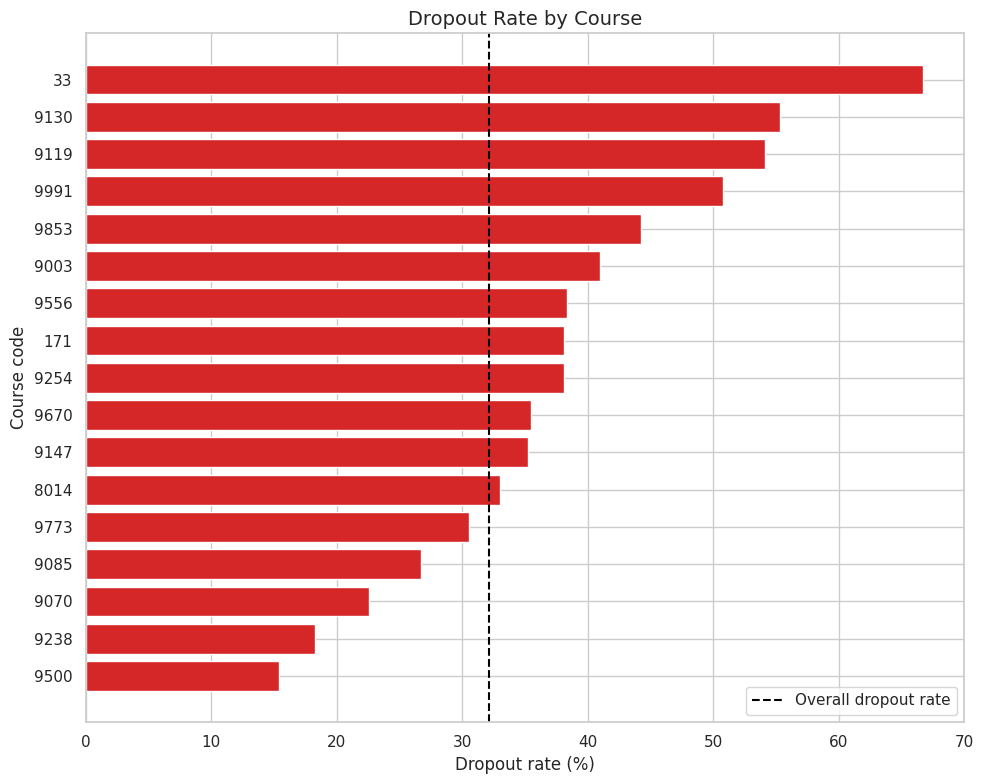

In [16]:
course_rates = (pd.crosstab(df["Course"], df["Target_label"], normalize="index")[class_order] * 100)
course_rates = course_rates.sort_values("Dropout")

plt.figure(figsize=(10, 8))
plt.barh(course_rates.index.astype(str), course_rates["Dropout"], color=palette["Dropout"])
plt.axvline((df["Target_label"] == "Dropout").mean() * 100, color="black",
            linestyle="--", label="Overall dropout rate")
plt.xlabel("Dropout rate (%)")
plt.ylabel("Course code")
plt.title("Dropout Rate by Course", fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

**Observations:**
- Dropout rates vary considerably between courses, from about 15% to about 67%, compared with an overall dropout rate of about 32% (dashed line).
- This suggests that the program of study is associated with dropout risk, so `Course` should be kept as a feature and **one-hot encoded** during preprocessing rather than used as a raw number.

### Summary of Relationship Insights

1. **1st and 2nd semester academic performance** (approved units and grades) shows the clearest association with the final outcome in the plots and the mutual information analysis.
2. **Financial features** (tuition fees status, scholarship, and debt) are associated with differences in dropout rates.
3. **Demographic features** such as age at enrollment and gender show moderate differences between outcome classes.
4. **Pre-university grades** and **macroeconomic indicators** show weaker associations.
5. The **1st and 2nd semester features are highly correlated with each other**, so the preprocessing step should address this redundancy.
6. The **Enrolled** class overlaps with both other classes in several plots. Whether it is actually the hardest class to predict will be verified with the evaluation results in Part B.

All findings in this section are **exploratory associations**. They do not establish cause and effect, and they do not show which features predict the outcome independently of the others.

### Note on Prediction Timing (Early Identification)

The features that show the strongest association with the outcome are the **1st and 2nd semester curricular unit features**. This information is **not available when a student first enrolls**. It only exists after the student has completed one or two semesters.

This affects what "early identification" can mean for our system:

| Prediction point | Features that can be used |
|---|---|
| **At enrollment** | Demographic, socioeconomic, application, and pre-university features, plus macroeconomic indicators for the enrollment year |
| **After the 1st semester** | All of the above, plus 1st semester curricular unit features |
| **After the 2nd semester** | All of the above, plus 2nd semester curricular unit features |

A model can only use the information available at the time the prediction is made. If the goal is to detect risk **before studies begin**, the semester features must be excluded. Including them would give results that look better than what the system could achieve in practice. The source also does not state exactly when some features (such as `Debtor` and `Tuition fees up to date`) were recorded, so their availability at each point should be confirmed.

**Decision:** Based on this analysis, the team decided to make predictions **after the 1st semester**. The model will use enrollment-time features and 1st semester curricular unit features (30 features in total), and the six 2nd semester features will be excluded. This gives academic advisors a full semester to intervene, keeps the grade information needed for the Phase 2 dashboard, and reduces the redundancy between the strongly correlated 1st and 2nd semester features.